# Analizo departamentos en venta en Mar del Plata

En este notebook realizo un análisis exploratorio, limpio los datos y preparo un conjunto final de departamentos con precios comparables en dólares. Documento cada decisión para que el proceso pueda revisarse y repetirse.

## Cómo sigo el notebook

Ejecuto las celdas **de arriba hacia abajo**, porque cada etapa utiliza el resultado de la anterior.

El recorrido de los datos es:

`Archivo Excel` → `propiedades` → `departamentos_limpios` → `departamentos_finales`

- En **`propiedades`** conservo los departamentos tal como ingresan al análisis.
- En **`departamentos_limpios`** corrijo formatos, valores inválidos, barrios y datos recuperables desde la descripción.
- En **`departamentos_finales`** elimino columnas sin información útil, dejo precios comparables en USD y retiro duplicados de coincidencia fuerte.

Cuando una tabla dice **antes**, se refiere a `propiedades`. Cuando dice **después**, se refiere a `departamentos_limpios`. El resultado que utilizo para continuar el análisis es `departamentos_finales`.

## 1. Preparo el entorno de trabajo

Importo las librerías que necesito y configuro cómo voy a mostrar tablas y gráficos. Esta celda no modifica los datos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.style.use('seaborn-v0_8-whitegrid')

DATA_PATH = Path('data/mitula_venta_mar_del_plata_SC.xlsx')
assert DATA_PATH.exists(), f'No se encontró {DATA_PATH.resolve()}'

## 2. Cargo los datos y defino el alcance

Leo la hoja `Propiedades` del archivo Excel y conservo únicamente los avisos clasificados como departamentos. Creo el DataFrame `propiedades`, que utilizo como punto de partida y no modifico durante la limpieza.

In [2]:
propiedades = pd.read_excel(
    DATA_PATH,
    sheet_name='Propiedades',
    engine='openpyxl'
)

cantidad_antes_filtro = len(propiedades)
propiedades = propiedades.loc[propiedades['tipo_propiedad'].eq('Departamento')].copy()
propiedades = propiedades.reset_index(drop=True)

print(f'Avisos antes del filtro: {cantidad_antes_filtro:,}')
print(f'Departamentos: {propiedades.shape[0]:,} filas × {propiedades.shape[1]} columnas')
display(propiedades.head(3))

Avisos antes del filtro: 4,274
Departamentos: 2,731 filas × 81 columnas


,id_aviso,tipo_propiedad,operacion,precio,moneda,precio_publicado,superficie_publicada,superficie_total_m2,superficie_cubierta_m2,superficie_descubierta_m2,superficie_semicubierta_m2,superficie_terreno_m2,ambientes,dormitorios,banos,toilettes,cocheras,antiguedad_anios,anio_construccion,piso,unidad,cantidad_plantas,frente_terreno_m,fondo_terreno_m,expensas,apto_credito,apto_profesional,escritura,estado,disposicion,orientacion,ubicacion,ciudad,partido,provincia,latitud,longitud,tipo_gas,portal_origen,id_aviso_origen,barrio,direccion,circunscripcion,seccion_catastral,manzana,parcela,chacra,titulo,descripcion,fecha_publicacion,actualizacion_relativa,anunciante,publicacion_destacada,amoblamiento,tiene_agua,tiene_aire_acondicionado,tiene_balcon,tiene_calefaccion,tiene_chimenea,tiene_cochera,tiene_electricidad,tiene_gas_natural,tiene_internet,tiene_parrilla,tiene_patio,tiene_piscina,tiene_terraza,tiene_jardin,tiene_ascensor,tiene_seguridad,tiene_wifi,tiene_lavadero,tiene_cocina_equipada,tiene_cocina_integral,tiene_cuarto_servicio,tiene_vista_panoramica,tiene_bodega,tiene_baulera,tiene_cloacas,url_aviso,url_listado
0,019c489b-6ed8-73ae-a54d-bbebeeb2900b,Departamento,venta,"124,800.00",USD,"124,800",41 m²,41.00,41.00,NaN,NaN,NaN,2.00,1.00,1.00,NaN,NaN,NaN,NaN,13.00,NaN,NaN,NaN,NaN,"140,000.00",Sí,NaN,NaN,reciclado,NaN,NaN,"Mar del Plata, General Pueyrredón",Mar del Plata,General Pueyrredón,Provincia de Buenos Aires,-38.01,-57.54,Gas natural / red,NaN,NaN,Plaza Colón,NaN,NaN,NaN,NaN,NaN,NaN,DUEÑO VENDE ! 2 amb reciclado vista al mar,"40 mt, balcón francés, 2 ambientes (1 habitaci...",30 jul 2026,NaN,Ezequiel grevi,Sí,NaN,NaN,NaN,Sí,Sí,NaN,NaN,NaN,Sí,NaN,NaN,NaN,NaN,NaN,NaN,Sí,Sí,NaN,NaN,Sí,Sí,NaN,Sí,NaN,NaN,NaN,https://casas.mitula.com.ar/adform/24301-256-7...,https://casas.mitula.com.ar/casas/st-partido-d...
1,019da4c5-0c4e-76a8-894b-7305efbf99fb,Departamento,venta,"90,900.00",USD,"90,900",41 m²,41.00,37.00,NaN,NaN,NaN,2.00,1.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Reciclado en totalidad (incluyendo cableado el...,NaN,NaN,"Mar del Plata, General Pueyrredón",Mar del Plata,General Pueyrredón,Provincia de Buenos Aires,-38.01,-57.54,NaN,NaN,NaN,Plaza Colón,NaN,NaN,NaN,NaN,NaN,NaN,Venta departamento 2 ambientes a la calle Plaz...,Departamento dos ambientes con balcón corrido ...,NaN,"Hace 4 días, 9 horas en - Indra Persic Propied...",Indra Persic Propiedades,Sí,NaN,Sí,Sí,Sí,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sí,NaN,https://casas.mitula.com.ar/adform/24301-256-7...,https://casas.mitula.com.ar/casas/st-partido-d...
2,019d6c20-b441-7c55-9e21-53352ab7b1a9,Departamento,venta,"64,900.00",USD,"64,900",28 m²,28.00,28.00,NaN,NaN,NaN,1.00,1.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,reciclado en su totalidad,Frente,NaN,"Mar del Plata, General Pueyrredón",Mar del Plata,General Pueyrredón,Provincia de Buenos Aires,-38.01,-57.54,NaN,NaN,NaN,Centro,NaN,NaN,NaN,NaN,NaN,NaN,VENTA departamento Plaza Colón Mar del Plata 1...,Departamento 1 ambiente dispuesto al frente co...,30 jul 2026,NaN,Indra Persic Propiedades,Sí,NaN,NaN,NaN,Sí,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://casas.mitula.com.ar/adform/24301-256-7...,https://casas.mitula.com.ar/casas/st-partido-d...


## 3. Conozco la estructura y la calidad inicial

Antes de corregir datos, observo cómo llegó el dataset. Llamo **faltante** a una celda sin información y **cobertura** al porcentaje de filas que sí tienen un valor.

### 3.1 Reviso todas las columnas

Para cada columna observo su tipo de dato, valores completos, faltantes, porcentaje de cobertura y cantidad de valores diferentes. Esta tabla concentra el diagnóstico de estructura y faltantes para evitar repetir cálculos.

In [3]:
resumen_estructura = pd.DataFrame({
    'tipo_dato': propiedades.dtypes.astype(str),
    'completos': propiedades.notna().sum(),
    'faltantes': propiedades.isna().sum(),
    'cobertura_pct': propiedades.notna().mean().mul(100).round(2),
    'valores_unicos': propiedades.nunique(dropna=True),
})
resumen_estructura.index.name = 'columna'
display(resumen_estructura)

,tipo_dato,completos,faltantes,cobertura_pct,valores_unicos
columna,,,,,
id_aviso,object,2731,0,100.00,2731
tipo_propiedad,object,2731,0,100.00,1
operacion,object,2731,0,100.00,1
precio,float64,2719,12,99.56,477
moneda,object,2719,12,99.56,2
precio_publicado,object,2719,12,99.56,477
superficie_publicada,object,2298,433,84.15,160
superficie_total_m2,float64,2313,418,84.69,180
superficie_cubierta_m2,float64,1256,1475,45.99,130


### 3.2 Controlo duplicados exactos

Compruebo si existen filas completamente repetidas, identificadores repetidos o URLs repetidas. Un duplicado exacto es una repetición evidente del mismo registro.

In [4]:
control_duplicados = pd.Series({
    'Filas duplicadas completas': propiedades.duplicated().sum(),
    'ID de aviso duplicado': propiedades['id_aviso'].duplicated().sum(),
    'URL de aviso duplicada': propiedades['url_aviso'].duplicated().sum(),
}, name='cantidad').to_frame()
display(control_duplicados)

,cantidad
Filas duplicadas completas,0
ID de aviso duplicado,0
URL de aviso duplicada,0


### 3.3 Controlo la calidad de los textos

Busco cadenas vacías y espacios innecesarios. Aunque visualmente parezcan valores faltantes, estos textos pueden estar almacenados como contenido y requieren una limpieza específica.

In [5]:
columnas_texto = propiedades.select_dtypes(include=['object', 'string']).columns
calidad_texto = pd.DataFrame({
    'valores_unicos': propiedades[columnas_texto].nunique(dropna=True),
    'cadenas_vacias': propiedades[columnas_texto].eq('').sum(),
    'solo_espacios': propiedades[columnas_texto].apply(
        lambda serie: serie.fillna('').astype(str).str.fullmatch(r'\s+').sum()
    ),
})
calidad_texto.index.name = 'columna'
display(calidad_texto)

,valores_unicos,cadenas_vacias,solo_espacios
columna,,,
id_aviso,2731,0,0
tipo_propiedad,1,0,0
operacion,1,0,0
moneda,2,0,0
precio_publicado,477,0,0
superficie_publicada,160,0,0
unidad,1,0,0
apto_credito,2,0,0
apto_profesional,1,0,0


## 4. Analizo todas las variables categóricas

Una variable categórica representa grupos o etiquetas, como moneda, barrio o estado. Recorro todas estas variables y muestro sus valores más frecuentes para detectar categorías inconsistentes o poco habituales.

In [6]:
categoricas = propiedades.select_dtypes(exclude='number').columns.tolist()

for columna in categoricas:
    cantidad_categorias = propiedades[columna].nunique(dropna=True)
    print(f'\nDistribución de {columna} ({cantidad_categorias:,} valores únicos)')
    print('Se muestran los 3 valores más frecuentes.')
    display(
        propiedades[columna].value_counts(dropna=False)
        .head(3).rename_axis(columna).to_frame('cantidad')
    )


Distribución de id_aviso (2,731 valores únicos)
Se muestran los 3 valores más frecuentes.


,cantidad
id_aviso,
019f03f2-735c-7df5-8b62-21b0ff822158,1
019c489b-6ed8-73ae-a54d-bbebeeb2900b,1
019da4c5-0c4e-76a8-894b-7305efbf99fb,1



Distribución de tipo_propiedad (1 valores únicos)
Se muestran los 3 valores más frecuentes.


,cantidad
tipo_propiedad,
Departamento,2731



Distribución de operacion (1 valores únicos)
Se muestran los 3 valores más frecuentes.


...


Distribución de url_aviso (2,731 valores únicos)
Se muestran los 3 valores más frecuentes.


,cantidad
url_aviso,
https://casas.mitula.com.ar/adform/24301-256-7ef5-21b0ff822258-8c62-19f04f2-745c?page=96&pos=29&t_sec=1&t_pvid=51529478-846e-4bef-bcb8-a5fc2cfa67f9&hd=false,1
https://casas.mitula.com.ar/adform/24301-256-74ae-bbebeeb2910b-a64d-19c499b-6fd8?page=1&pos=1&t_sec=1&t_pvid=10bee824-8b3d-4199-af0c-ea180adf6c08&hd=false,1
https://casas.mitula.com.ar/adform/24301-256-77a8-7305efbf9afb-8a4b-19da5c5-d4e?page=1&pos=2&t_sec=1&t_pvid=10bee824-8b3d-4199-af0c-ea180adf6c08&hd=false,1



Distribución de url_listado (196 valores únicos)


Se muestran los 3 valores más frecuentes.


,cantidad
url_listado,
https://casas.mitula.com.ar/casas/st-partido-de-general-pueyrredon-buenos-aires?page=97,57
https://casas.mitula.com.ar/casas/st-partido-de-general-pueyrredon-buenos-aires?page=95,54
https://casas.mitula.com.ar/casas/st-partido-de-general-pueyrredon-buenos-aires?page=96,50


## 5. Analizo todas las variables numéricas

Identifico todas las columnas numéricas y calculo medidas como mínimo, máximo, promedio, mediana y percentiles. Estas medidas me permiten comprender la escala y la distribución de los valores.

In [7]:
numericas = propiedades.select_dtypes(include='number').columns.tolist()
print(f'Cantidad de columnas numéricas: {len(numericas)}')
display(pd.DataFrame({'columna_numerica': numericas}))

resumen_numericas = (
    propiedades[numericas]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)
display(resumen_numericas)

Cantidad de columnas numéricas: 23


,columna_numerica
0,precio
1,superficie_total_m2
2,superficie_cubierta_m2
3,superficie_descubierta_m2
4,superficie_semicubierta_m2
5,superficie_terreno_m2
6,ambientes
7,dormitorios
8,banos
9,toilettes


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
columna,,,,,,,,,,,,
precio,"2,719.00","116,842.16","105,262.54",1.00,"39,000.00","48,000.00","67,900.00","94,000.00","134,900.00","250,000.00","450,000.00","2,690,000.00"
superficie_total_m2,"2,313.00",64.52,131.06,1.00,21.00,26.00,39.00,51.00,70.00,126.40,222.64,"5,360.00"
superficie_cubierta_m2,"1,256.00",60.75,75.83,1.00,19.55,25.00,38.00,50.00,68.62,112.00,187.80,"2,007.00"
superficie_descubierta_m2,7.00,6.60,3.33,4.30,4.34,4.49,4.94,6.00,6.00,11.60,13.52,14.00
superficie_semicubierta_m2,1.00,14.00,NaN,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00
superficie_terreno_m2,"1,491.00","3,021.71","59,499.57",8.00,21.00,25.00,39.00,51.00,70.50,140.00,377.50,"1,750,000.00"
ambientes,"2,230.00",32.49,"1,333.44",1.00,1.00,1.00,2.00,2.00,3.00,4.00,4.00,"62,900.00"
dormitorios,"2,296.00",1.62,0.77,1.00,1.00,1.00,1.00,1.00,2.00,3.00,4.00,12.00
banos,"2,705.00",1.40,1.78,1.00,1.00,1.00,1.00,1.00,2.00,2.00,3.00,55.00


### 5.1 Detecto valores numéricos sospechosos

Reviso ceros, negativos y valores extremos. También aplico el rango intercuartílico —una regla estadística— para señalar posibles valores atípicos. En esta etapa solo los identifico: todavía no los elimino ni los modifico.

In [8]:
q1 = propiedades[numericas].quantile(0.25)
q3 = propiedades[numericas].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

diagnostico_numerico = pd.DataFrame({
    'mínimo': propiedades[numericas].min(),
    'percentil_01': propiedades[numericas].quantile(0.01),
    'mediana': propiedades[numericas].median(),
    'percentil_99': propiedades[numericas].quantile(0.99),
    'máximo': propiedades[numericas].max(),
    'ceros': propiedades[numericas].eq(0).sum(),
    'negativos': propiedades[numericas].lt(0).sum(),
    'posibles_atípicos_iqr': (
        propiedades[numericas].lt(limite_inferior)
        | propiedades[numericas].gt(limite_superior)
    ).sum(),
})
display(diagnostico_numerico)

,mínimo,percentil_01,mediana,percentil_99,máximo,ceros,negativos,posibles_atípicos_iqr
columna,,,,,,,,
precio,1.00,"39,000.00","94,000.00","450,000.00","2,690,000.00",0,0,160
superficie_total_m2,1.00,21.00,51.00,222.64,"5,360.00",0,0,144
superficie_cubierta_m2,1.00,19.55,50.00,187.80,"2,007.00",0,0,61
superficie_descubierta_m2,4.30,4.34,6.00,13.52,14.00,0,0,1
superficie_semicubierta_m2,14.00,14.00,14.00,14.00,14.00,0,0,0
superficie_terreno_m2,8.00,21.00,51.00,377.50,"1,750,000.00",0,0,113
ambientes,1.00,1.00,2.00,4.00,"62,900.00",0,0,19
dormitorios,1.00,1.00,1.00,4.00,12.00,0,0,33
banos,1.00,1.00,1.00,3.00,55.00,0,0,27


### 5.2 Observo las distribuciones numéricas

Grafico todas las variables numéricas. Cada histograma muestra en qué rangos se concentran los datos y ayuda a reconocer asimetrías, valores extremos y escalas inusuales.

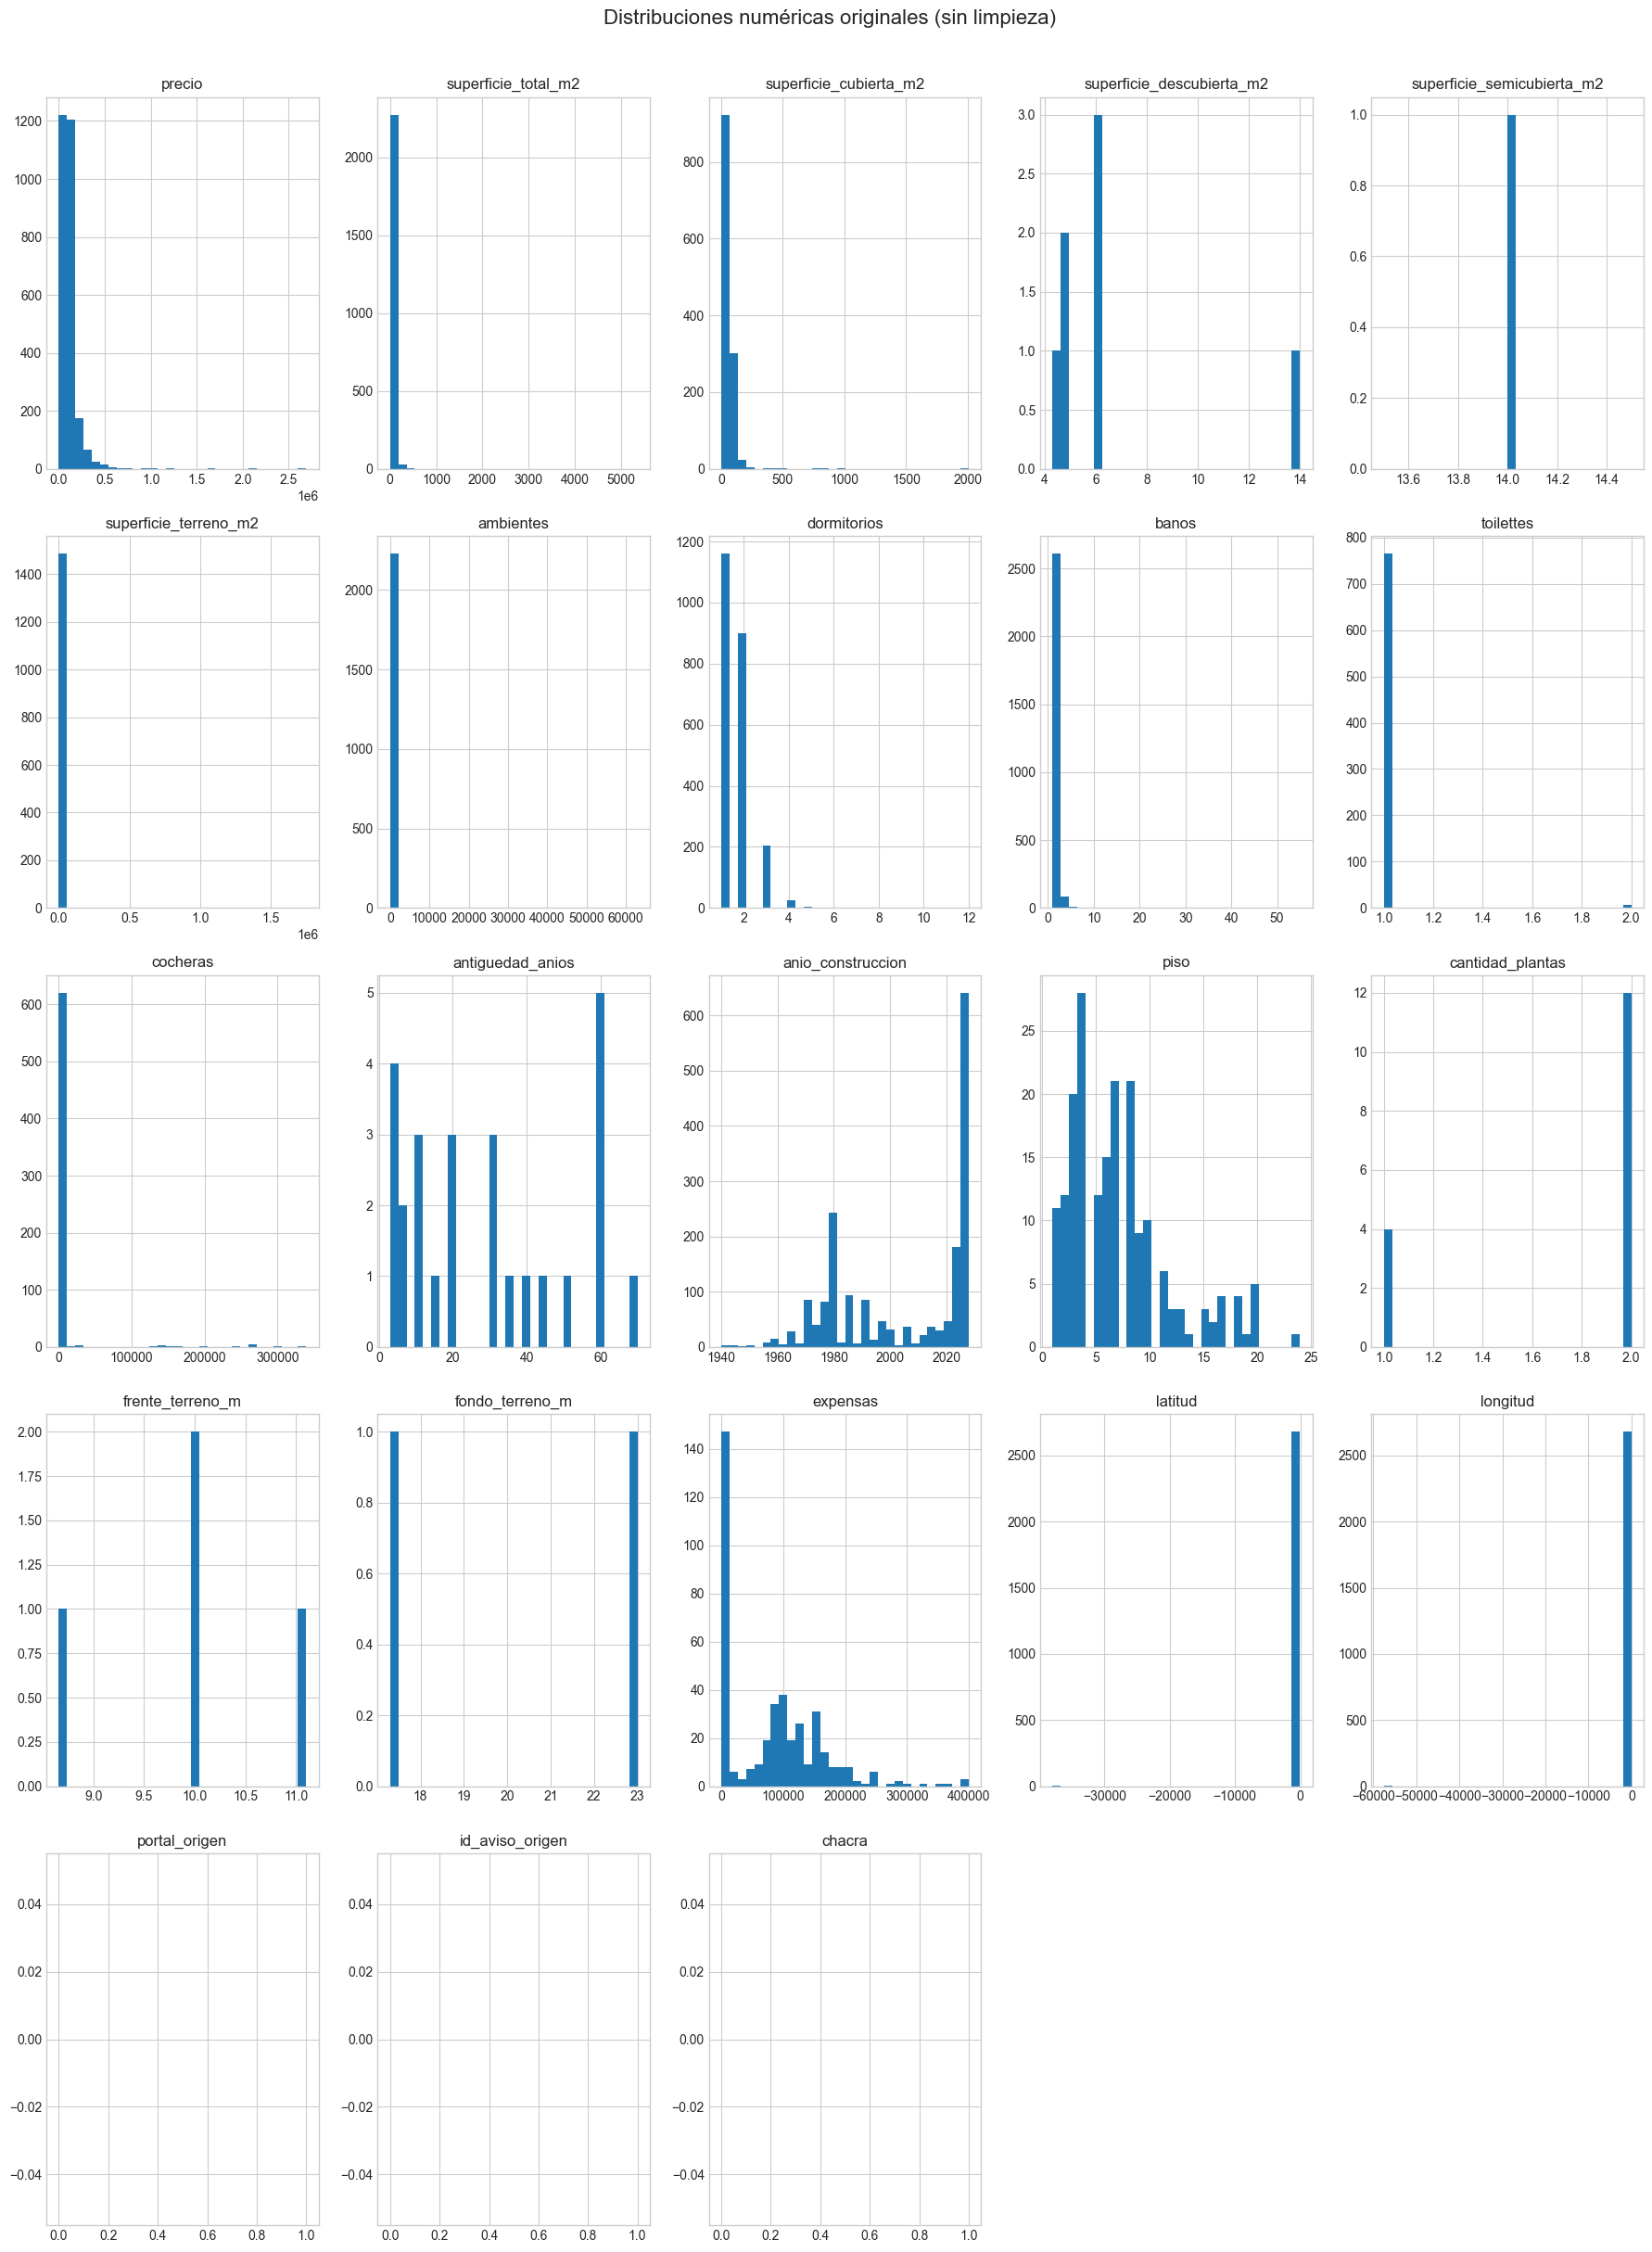

In [9]:
propiedades[numericas].hist(figsize=(18, 24), bins=30)
plt.suptitle('Distribuciones numéricas originales (sin limpieza)', y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

## 6. Reviso la coherencia de los registros

Además de estudiar cada columna por separado, compruebo si los valores de una misma fila son compatibles entre sí. Por ejemplo, reviso si la superficie cubierta supera a la total o si la cantidad de dormitorios supera a la de ambientes.

### 6.1 Cuento las inconsistencias

Aplico reglas de integridad, rangos y coherencia lógica. Obtengo la cantidad de registros que incumple cada regla, pero no modifico todavía las observaciones.

In [10]:
anio_actual = pd.Timestamp.now().year

validaciones = {
    # Valido la identificación y los duplicados
    'ID de aviso faltante': propiedades['id_aviso'].isna(),
    'ID de aviso duplicado': propiedades['id_aviso'].duplicated(),
    'URL de aviso faltante': propiedades['url_aviso'].isna(),
    'URL de aviso duplicada': propiedades['url_aviso'].duplicated(),
    'Título faltante': propiedades['titulo'].isna(),
    'Descripción faltante': propiedades['descripcion'].isna(),

    # Valido el precio y la moneda
    'Precio faltante': propiedades['precio'].isna(),
    'Moneda faltante': propiedades['moneda'].isna(),
    'Precio informado sin moneda': propiedades['precio'].notna() & propiedades['moneda'].isna(),
    'Moneda informada sin precio': propiedades['moneda'].notna() & propiedades['precio'].isna(),
    'Precio menor o igual a cero': propiedades['precio'].le(0),
    'Precio inferior a 5.000': propiedades['precio'].between(0, 5_000, inclusive='neither'),
    'Precio superior a 10.000.000': propiedades['precio'].gt(10_000_000),
    'Moneda fuera de USD o ARS': propiedades['moneda'].notna() & ~propiedades['moneda'].isin(['USD', 'ARS']),

    # Valido las superficies y las dimensiones
    'Superficie total menor o igual a cero': propiedades['superficie_total_m2'].le(0),
    'Superficie cubierta menor o igual a cero': propiedades['superficie_cubierta_m2'].le(0),
    'Superficie descubierta menor o igual a cero': propiedades['superficie_descubierta_m2'].le(0),
    'Superficie semicubierta menor o igual a cero': propiedades['superficie_semicubierta_m2'].le(0),
    'Superficie de terreno menor o igual a cero': propiedades['superficie_terreno_m2'].le(0),
    'Superficie cubierta mayor que total': propiedades['superficie_cubierta_m2'] > propiedades['superficie_total_m2'],
    'Superficie descubierta mayor que total': propiedades['superficie_descubierta_m2'] > propiedades['superficie_total_m2'],
    'Superficie semicubierta mayor que total': propiedades['superficie_semicubierta_m2'] > propiedades['superficie_total_m2'],
    'Total superior a 10 veces el terreno': propiedades['superficie_total_m2'] > propiedades['superficie_terreno_m2'] * 10,
    'Cubierta superior a 2 veces el total': propiedades['superficie_cubierta_m2'] > propiedades['superficie_total_m2'] * 2,
    'Frente del terreno menor o igual a cero': propiedades['frente_terreno_m'].le(0),
    'Fondo del terreno menor o igual a cero': propiedades['fondo_terreno_m'].le(0),
    'Frente del terreno superior a 100 metros': propiedades['frente_terreno_m'].gt(100),
    'Fondo del terreno superior a 200 metros': propiedades['fondo_terreno_m'].gt(200),

    # Valido las cantidades
    'Ambientes menores que 1': propiedades['ambientes'].lt(1),
    'Ambientes mayores que 20': propiedades['ambientes'].gt(20),
    'Dormitorios menores que 1': propiedades['dormitorios'].lt(1),
    'Dormitorios mayores que 15': propiedades['dormitorios'].gt(15),
    'Baños menores que 1': propiedades['banos'].lt(1),
    'Baños mayores que 15': propiedades['banos'].gt(15),
    'Toilettes mayores que 10': propiedades['toilettes'].gt(10),
    'Cocheras negativas': propiedades['cocheras'].lt(0),
    'Cocheras mayores que 20': propiedades['cocheras'].gt(20),
    'Ambientes no enteros': propiedades['ambientes'].notna() & propiedades['ambientes'].mod(1).ne(0),
    'Dormitorios no enteros': propiedades['dormitorios'].notna() & propiedades['dormitorios'].mod(1).ne(0),
    'Baños no enteros': propiedades['banos'].notna() & propiedades['banos'].mod(1).ne(0),
    'Cocheras no enteras': propiedades['cocheras'].notna() & propiedades['cocheras'].mod(1).ne(0),
    'Dormitorios mayores que ambientes': propiedades['dormitorios'] > propiedades['ambientes'],
    'Baños mayores que ambientes': propiedades['banos'] > propiedades['ambientes'],

    # Valido la construcción, los pisos y las expensas
    'Antigüedad negativa': propiedades['antiguedad_anios'].lt(0),
    'Antigüedad superior a 200 años': propiedades['antiguedad_anios'].gt(200),
    'Año de construcción anterior a 1800': propiedades['anio_construccion'].lt(1800),
    'Año de construcción posterior a 10 años': propiedades['anio_construccion'].gt(anio_actual + 10),
    'Piso negativo': propiedades['piso'].lt(0),
    'Piso superior a 100': propiedades['piso'].gt(100),
    'Cantidad de plantas menor que 1': propiedades['cantidad_plantas'].lt(1),
    'Cantidad de plantas superior a 10': propiedades['cantidad_plantas'].gt(10),
    'Expensas negativas': propiedades['expensas'].lt(0),

    # Valido las coordenadas y el alcance geográfico
    'Latitud sin longitud': propiedades['latitud'].notna() & propiedades['longitud'].isna(),
    'Longitud sin latitud': propiedades['longitud'].notna() & propiedades['latitud'].isna(),
    'Latitud fuera del área de Mar del Plata': propiedades['latitud'].notna() & ~propiedades['latitud'].between(-39, -37),
    'Longitud fuera del área de Mar del Plata': propiedades['longitud'].notna() & ~propiedades['longitud'].between(-59, -56),
    'Tipo de propiedad diferente de Departamento': propiedades['tipo_propiedad'].notna() & propiedades['tipo_propiedad'].ne('Departamento'),
    'Operación diferente de venta': propiedades['operacion'].notna() & propiedades['operacion'].str.lower().ne('venta'),
}

inconsistencias = pd.Series(
    {nombre: mascara.fillna(False).sum() for nombre, mascara in validaciones.items()},
    name='cantidad'
).to_frame()
inconsistencias['porcentaje'] = inconsistencias['cantidad'].div(len(propiedades)).mul(100).round(2)
inconsistencias = inconsistencias.sort_values('cantidad', ascending=False)
display(inconsistencias)

print('Estas reglas son diagnósticas y no modifican el dataset.')

,cantidad,porcentaje
Superficie cubierta mayor que total,74,2.71
Descripción faltante,51,1.87
Cocheras mayores que 20,24,0.88
Moneda faltante,12,0.44
Baños mayores que ambientes,12,0.44
Precio faltante,12,0.44
Dormitorios mayores que ambientes,11,0.40
Baños no enteros,5,0.18
Baños mayores que 15,4,0.15
Precio inferior a 5.000,3,0.11


Estas reglas son diagnósticas y no modifican el dataset.


### 6.2 Observo ejemplos concretos

Muestro una selección de las filas que activaron alguna validación. Así puedo interpretar los problemas con su título, descripción, precio y demás datos relacionados.

In [11]:
columnas_contexto = [
    'id_aviso', 'tipo_propiedad', 'precio', 'moneda',
    'superficie_total_m2', 'ambientes', 'dormitorios', 'banos',
    'cocheras', 'titulo', 'descripcion', 'url_aviso'
]
columnas_contexto = [columna for columna in columnas_contexto if columna in propiedades.columns]

def revisar_inconsistencia(nombre, cantidad=10):
    if nombre not in validaciones:
        raise ValueError(f'Validación inexistente: {nombre}')
    mascara = validaciones[nombre].fillna(False)
    print(f'{nombre}: {mascara.sum()} registros')
    display(propiedades.loc[mascara, columnas_contexto].head(cantidad))

print('Usá revisar_inconsistencia(nombre) solo cuando necesites investigar un problema.')
display(inconsistencias.loc[inconsistencias['cantidad'].gt(0)])

Usá revisar_inconsistencia(nombre) solo cuando necesites investigar un problema.


,cantidad,porcentaje
Superficie cubierta mayor que total,74,2.71
Descripción faltante,51,1.87
Cocheras mayores que 20,24,0.88
Moneda faltante,12,0.44
Baños mayores que ambientes,12,0.44
Precio faltante,12,0.44
Dormitorios mayores que ambientes,11,0.40
Baños no enteros,5,0.18
Baños mayores que 15,4,0.15
Precio inferior a 5.000,3,0.11


### 6.3 Genero candidatos a duplicados semánticos

Busco publicaciones que podrían representar la misma propiedad aunque tengan identificadores y URLs diferentes. En este primer control solo genero candidatos mediante título, precio y superficie; no elimino registros.

In [12]:
claves_duplicado = ['titulo', 'precio', 'superficie_total_m2']
posibles_duplicados = propiedades.loc[
    propiedades.duplicated(subset=claves_duplicado, keep=False),
    ['id_aviso', 'titulo', 'precio', 'moneda', 'superficie_total_m2',
     'direccion', 'anunciante', 'url_aviso']
].sort_values(claves_duplicado)

print(f'Registros candidatos a duplicados semánticos: {len(posibles_duplicados):,}')
display(posibles_duplicados.head(100))

Registros candidatos a duplicados semánticos: 47


columna,id_aviso,titulo,precio,moneda,superficie_total_m2,direccion,anunciante,url_aviso
1130,019fd9ba-82b1-76ca-86dc-6cdc44d10cb7,2 ambientes al frente c/ balcón- ideal inversion,"91,500.00",USD,39.00,NaN,Gabilan Loustaunau Propiedades,https://casas.mitula.com.ar/adform/24301-256-7...
1916,01a05a82-8659-7310-b779-91a12b07efd0,2 ambientes al frente c/ balcón- ideal inversion,"91,500.00",USD,39.00,NaN,Gabilan Loustaunau Propiedades,https://casas.mitula.com.ar/adform/24301-256-7...
922,019f0258-43bf-77e0-b49c-8a189eff530c,Departamento 1 Ambiente,"46,000.00",USD,36.00,NaN,CAIONE & AYALA,https://casas.mitula.com.ar/adform/24301-256-7...
923,019f0258-35d5-7243-a0d5-a845b19c3389,Departamento 1 Ambiente,"46,000.00",USD,36.00,NaN,CAIONE & AYALA,https://casas.mitula.com.ar/adform/24301-256-7...
2189,019af8fd-1e30-7515-a3eb-e83d5a97ef08,Departamento Monoambiente en venta - 1 Baño - ...,"51,900.00",USD,26.00,NaN,Yacoub Real Estate & Developers,https://casas.mitula.com.ar/adform/24301-256-7...
2194,019ab5fe-89b9-75cc-809e-7ff6a3092a5d,Departamento Monoambiente en venta - 1 Baño - ...,"51,900.00",USD,26.00,NaN,Yacoub Real Estate & Developers,https://casas.mitula.com.ar/adform/24301-256-7...
1337,019ecde4-9b31-7c30-b4ab-2cadd84cae58,Departamento de 1 ambiente en VENTA,"54,900.00",USD,26.00,NaN,Bellucci Propiedades,https://casas.mitula.com.ar/adform/24301-256-7...
2448,019f2fb7-e698-7f18-bc05-173886321dc7,Departamento de 1 ambiente en VENTA,"54,900.00",USD,26.00,NaN,Bellucci Propiedades,https://casas.mitula.com.ar/adform/24301-256-8...
1373,01a002ed-6e68-7b37-a740-44d88c4dd6e8,Departamento de un ambiente zona Güemes Mar de...,"92,000.00",USD,39.00,NaN,Galan Broker Inmobiliario®,https://casas.mitula.com.ar/adform/24301-256-7...
1374,01a002ec-8a4e-7705-ac44-9a51378b1e7c,Departamento de un ambiente zona Güemes Mar de...,"92,000.00",USD,39.00,NaN,Galan Broker Inmobiliario®,https://casas.mitula.com.ar/adform/24301-256-7...


## 7. Reviso las fechas y las coordenadas

### 7.1 Reviso las fechas

Convierto las columnas temporales disponibles y observo sus rangos. Esto me permite detectar fechas inválidas o fuera del período esperado.

In [13]:
columnas_temporales = [
    columna for columna in ['fecha_publicacion', 'fecha_scraping_utc']
    if columna in propiedades.columns
]
for columna in columnas_temporales:
    fechas = pd.to_datetime(propiedades[columna], errors='coerce', utc=True)
    print(f'{columna}:')
    print(f'  Fechas válidas: {fechas.notna().sum():,}')
    print(f'  No interpretables o faltantes: {fechas.isna().sum():,}')
    print(f'  Mínimo: {fechas.min()}')
    print(f'  Máximo: {fechas.max()}')

fecha_publicacion:
  Fechas válidas: 1,771
  No interpretables o faltantes: 960
  Mínimo: 2026-05-19 00:00:00+00:00
  Máximo: 2026-07-31 00:00:00+00:00


C:\Users\Joaquin\AppData\Local\Temp\ipykernel_23008\3506234452.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  fechas = pd.to_datetime(propiedades[columna], errors='coerce', utc=True)


### 7.2 Reviso las coordenadas

Resumo y grafico la latitud y la longitud. Utilizo esta revisión para detectar coordenadas faltantes, errores de escala y puntos fuera del área esperada.

,count,mean,std,min,25%,50%,75%,max
columna,,,,,,,,
latitud,"2,680.00",-52.16,732.60,"-37,964.00",-38.01,-38.00,-38.00,-37.91
longitud,"2,680.00",-100.46,"1,570.40","-57,558.00",-57.55,-57.55,-57.54,-57.52


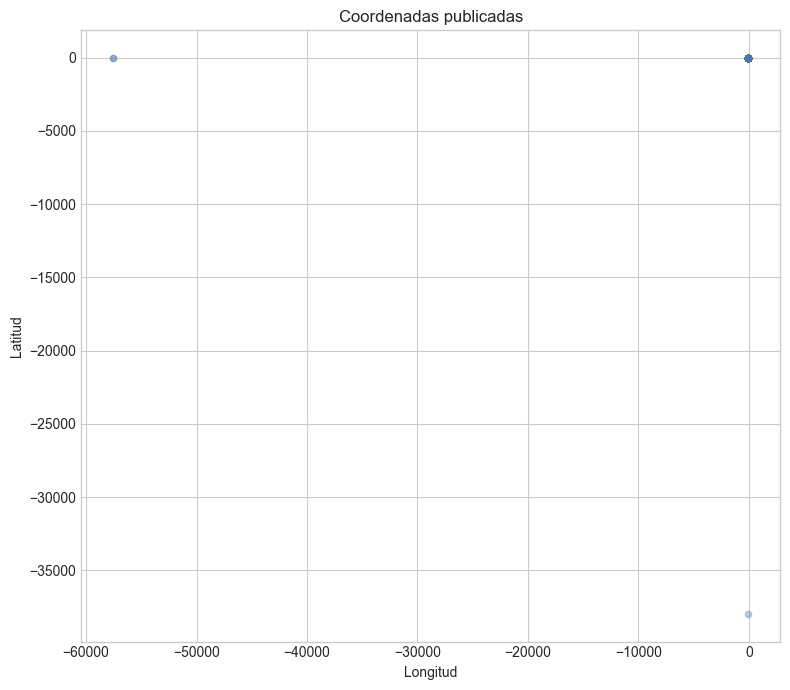

In [14]:
resumen_coordenadas = propiedades[['latitud', 'longitud']].describe().T
display(resumen_coordenadas)

ax = propiedades.plot.scatter(
    x='longitud', y='latitud', figsize=(8, 7), alpha=0.35, color='#4C78A8'
)
ax.set_title('Coordenadas publicadas')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
plt.tight_layout()
plt.show()

## 8. Limpio y completo los datos

A partir de esta etapa trabajo sobre una copia llamada `departamentos_limpios`. Mantengo `propiedades` sin modificaciones para poder comparar el antes y el después. Todavía no creo variables derivadas.

### 8.1 Creo la copia de trabajo y la auditoría

Creo `departamentos_limpios` como una copia independiente. También preparo una auditoría donde registro qué variable modifico, qué acción realizo y cuántas filas resultan afectadas.

In [15]:
import json
import re

departamentos_limpios = propiedades.copy(deep=True)
auditoria_limpieza = []

def registrar(etapa, variable, accion, cantidad):
    auditoria_limpieza.append({
        'etapa': etapa, 'variable': variable, 'accion': accion,
        'cantidad_afectada': int(cantidad)
    })

print(f'Copia de trabajo: {departamentos_limpios.shape[0]:,} filas × {departamentos_limpios.shape[1]} columnas')

Copia de trabajo: 2,731 filas × 81 columnas


### 8.2 Limpio los textos y ajusto el alcance

Elimino espacios innecesarios, convierto cadenas vacías en valores faltantes y separo publicaciones que identifico claramente como hoteles, alquileres temporarios, fondos de comercio u otros casos ajenos a departamentos residenciales en venta.

In [16]:
# Recorto los espacios y convierto las cadenas vacías en NA.
for columna in departamentos_limpios.select_dtypes(include=['object', 'string']).columns:
    antes = departamentos_limpios[columna].copy()
    departamentos_limpios[columna] = (
        departamentos_limpios[columna].astype('string')
        .str.replace('\u00a0', ' ', regex=False).str.strip().replace('', pd.NA)
    )
    cambios = antes.fillna('<NA>').astype(str).ne(
        departamentos_limpios[columna].fillna('<NA>').astype(str)
    ).sum()
    if cambios:
        registrar('Texto', columna, 'Espacios corregidos o vacío a NA', cambios)

# Separo las publicaciones que identifico inequívocamente como ajenas a departamentos residenciales en venta.
patron_fuera_alcance = r'(?i)hotel|hostel|geri.tric|alquiler temporario|fondo de comercio|\bvendido\b'
mascara_fuera_alcance = departamentos_limpios['titulo'].str.contains(
    patron_fuera_alcance, regex=True, na=False
)
departamentos_excluidos = departamentos_limpios.loc[mascara_fuera_alcance].copy()
registrar('Alcance', 'fila', 'Aviso no residencial, temporario o vendido', mascara_fuera_alcance.sum())
departamentos_limpios = departamentos_limpios.loc[~mascara_fuera_alcance].copy().reset_index(drop=True)
print('Registros separados por alcance:', len(departamentos_excluidos))

Registros separados por alcance: 12


### 8.3 Normalizo categorías y respuestas binarias

Unifico nombres equivalentes, como las variantes de provincia, y estandarizo respuestas binarias para que utilicen únicamente `Sí`, `No` o un valor faltante.

In [17]:
# Normalizo las categorías geográficas y binarias inequívocas.
antes = departamentos_limpios['provincia'].copy()
departamentos_limpios['provincia'] = departamentos_limpios['provincia'].replace(
    {'Buenos Aires': 'Provincia de Buenos Aires'}
)
registrar('Categorías', 'provincia', 'Nombre unificado', antes.ne(departamentos_limpios['provincia']).sum())

columnas_binarias = [columna for columna in departamentos_limpios.columns if (
    columna.startswith('tiene_') or columna in {
        'apto_credito', 'apto_profesional', 'escritura', 'publicacion_destacada', 'detalle_extraido'
    }
)]

def normalizar_binaria(valor):
    if pd.isna(valor):
        return pd.NA
    texto = str(valor).strip().casefold()
    if texto in {'si', 'sí', 'true', '1'}:
        return 'Sí'
    if texto in {'no', 'false', '0'}:
        return 'No'
    return pd.NA

for columna in columnas_binarias:
    antes = departamentos_limpios[columna].copy()
    departamentos_limpios[columna] = departamentos_limpios[columna].map(normalizar_binaria).astype('string')
    cambios = antes.fillna('<NA>').astype(str).ne(
        departamentos_limpios[columna].fillna('<NA>').astype(str)
    ).sum()
    if cambios:
        registrar('Categorías', columna, 'Sí/No normalizado', cambios)

### 8.4 Trato valores numéricos inválidos

Defino rangos razonables para precios, superficies, cantidades y años. Cuando un valor es imposible o claramente erróneo lo convierto en faltante, porque no dispongo de evidencia suficiente para inventar su valor correcto.

In [18]:
reglas_rango = {
    'precio': (5_000, 5_000_000),
    'superficie_total_m2': (10, 1_000),
    'superficie_cubierta_m2': (10, 1_000),
    'superficie_descubierta_m2': (0, 1_000),
    'superficie_semicubierta_m2': (0, 1_000),
    'superficie_terreno_m2': (0, 2_000),
    'ambientes': (1, 15), 'dormitorios': (1, 10),
    'banos': (1, 10), 'toilettes': (1, 10), 'cocheras': (0, 10),
    'antiguedad_anios': (0, 200), 'piso': (0, 100),
    'cantidad_plantas': (1, 10), 'frente_terreno_m': (0, 100),
    'fondo_terreno_m': (0, 200), 'expensas': (0, 10_000_000),
}
for columna, (minimo, maximo) in reglas_rango.items():
    serie = pd.to_numeric(departamentos_limpios[columna], errors='coerce')
    mascara = serie.notna() & ~serie.between(minimo, maximo)
    registrar('Rangos', columna, f'Fuera de {minimo}–{maximo} a NA', mascara.sum())
    departamentos_limpios[columna] = serie.mask(mascara)

columnas_enteras = ['ambientes', 'dormitorios', 'banos', 'toilettes', 'cocheras', 'piso', 'cantidad_plantas']
for columna in columnas_enteras:
    mascara = departamentos_limpios[columna].notna() & departamentos_limpios[columna].mod(1).ne(0)
    registrar('Rangos', columna, 'Valor no entero a NA', mascara.sum())
    departamentos_limpios.loc[mascara, columna] = np.nan
    departamentos_limpios[columna] = departamentos_limpios[columna].astype('Int64')

mascara_anio = departamentos_limpios['anio_construccion'].notna() & ~departamentos_limpios['anio_construccion'].between(1800, pd.Timestamp.now().year + 10)
registrar('Rangos', 'anio_construccion', 'Año no plausible a NA', mascara_anio.sum())
departamentos_limpios.loc[mascara_anio, 'anio_construccion'] = np.nan
departamentos_limpios['anio_construccion'] = departamentos_limpios['anio_construccion'].astype('Int64')

mascara_cubierta = departamentos_limpios['superficie_cubierta_m2'] > departamentos_limpios['superficie_total_m2'] * 2
registrar('Coherencia', 'superficie_cubierta_m2', 'Cubierta >2 veces total a NA', mascara_cubierta.sum())
departamentos_limpios.loc[mascara_cubierta, 'superficie_cubierta_m2'] = np.nan

### 8.5 Preparo la cartografía de barrios

Cargo un archivo geográfico público con los límites de los barrios y defino las funciones necesarias para comprobar dentro de qué polígono se encuentra cada coordenada.

In [19]:
GEOJSON_PATH = Path('data/barrios_mar_del_plata.geojson')
assert GEOJSON_PATH.exists(), f'No se encontró {GEOJSON_PATH.resolve()}'
with GEOJSON_PATH.open(encoding='utf-8') as archivo:
    geojson_barrios = json.load(archivo)

def punto_en_anillo(x, y, anillo):
    dentro = False
    j = len(anillo) - 1
    for i in range(len(anillo)):
        xi, yi = anillo[i][:2]
        xj, yj = anillo[j][:2]
        cruza = ((yi > y) != (yj > y)) and (x < (xj - xi) * (y - yi) / ((yj - yi) or 1e-15) + xi)
        if cruza:
            dentro = not dentro
        j = i
    return dentro

def punto_en_poligono(x, y, poligono):
    return punto_en_anillo(x, y, poligono[0]) and not any(
        punto_en_anillo(x, y, hueco) for hueco in poligono[1:]
    )

poligonos_barrios = []
for feature in geojson_barrios['features']:
    nombre = feature['properties'].get('soc_fomen')
    geometria = feature['geometry']
    poligonos = geometria['coordinates'] if geometria['type'] == 'MultiPolygon' else [geometria['coordinates']]
    for poligono in poligonos:
        xs = [p[0] for p in poligono[0]]
        ys = [p[1] for p in poligono[0]]
        poligonos_barrios.append((nombre, poligono, min(xs), max(xs), min(ys), max(ys)))

def obtener_barrio(longitud, latitud):
    if pd.isna(longitud) or pd.isna(latitud):
        return pd.NA
    for nombre, poligono, xmin, xmax, ymin, ymax in poligonos_barrios:
        if xmin <= longitud <= xmax and ymin <= latitud <= ymax and punto_en_poligono(longitud, latitud, poligono):
            return str(nombre).title()
    return pd.NA

### 8.6 Corrijo coordenadas y normalizo barrios

Corrijo únicamente errores inequívocos de escala y cruzo cada par de coordenadas con la cartografía. Utilizo el barrio geográfico resultante para completar y unificar la columna `barrio` en `departamentos_limpios`.

In [20]:
# Corrijo el error de escala que observo en coordenadas puntuales.
mascara_latitud_escala = departamentos_limpios['latitud'].between(-39_000, -37_000)
mascara_longitud_escala = departamentos_limpios['longitud'].between(-59_000, -56_000)
registrar('Coordenadas', 'latitud', 'Escala /1000', mascara_latitud_escala.sum())
registrar('Coordenadas', 'longitud', 'Escala /1000', mascara_longitud_escala.sum())
departamentos_limpios.loc[mascara_latitud_escala, 'latitud'] /= 1_000
departamentos_limpios.loc[mascara_longitud_escala, 'longitud'] /= 1_000

barrios_por_coordenadas = pd.Series(
    [obtener_barrio(lon, lat) for lon, lat in zip(departamentos_limpios['longitud'], departamentos_limpios['latitud'])],
    index=departamentos_limpios.index, dtype='string'
)
mascara_barrio_geografico = barrios_por_coordenadas.notna()
barrios_antes = departamentos_limpios['barrio'].copy()
departamentos_limpios.loc[mascara_barrio_geografico, 'barrio'] = barrios_por_coordenadas[mascara_barrio_geografico]
cambios_barrio = barrios_antes.fillna('<NA>').astype(str).ne(
    departamentos_limpios['barrio'].fillna('<NA>').astype(str)
)
registrar('Completado', 'barrio', 'Barrio cartográfico por punto en polígono', cambios_barrio.sum())
print('Barrios asignados geográficamente:', mascara_barrio_geografico.sum())
print('Barrios aún faltantes:', departamentos_limpios['barrio'].isna().sum())
print('Valores de barrio modificados o completados:', cambios_barrio.sum())

Barrios asignados geográficamente: 2648
Barrios aún faltantes: 36
Valores de barrio modificados o completados: 2436


### 8.7 Completo valores numéricos desde la descripción

Busco menciones explícitas de superficies, ambientes, dormitorios, baños, cocheras, antigüedad, año y expensas. Reconozco sinónimos, abreviaturas, singular, plural y cantidades escritas con palabras. Solo completo campos vacíos y acepto valores dentro de rangos válidos.

In [21]:
# Normalizo los acentos y las mayúsculas únicamente para realizar las búsquedas.
# Mantengo la descripción original sin modificaciones.
texto = departamentos_limpios['descripcion'].fillna('').astype(str)
texto_normalizado = (
    texto.str.replace('²', '2', regex=False)
    .str.normalize('NFKD')
    .str.encode('ascii', errors='ignore')
    .str.decode('utf-8')
    .str.lower()
)

def numero_argentino(serie):
    equivalencias = {
        'mono': '1', 'un': '1', 'uno': '1', 'una': '1',
        'dos': '2', 'tres': '3', 'cuatro': '4', 'cinco': '5',
        'seis': '6', 'siete': '7', 'ocho': '8', 'nueve': '9', 'diez': '10',
    }
    limpio = (
        serie.astype('string').replace(equivalencias)
        .str.replace(r'[$\s]', '', regex=True)
        .str.replace('.', '', regex=False)
        .str.replace(',', '.', regex=False)
    )
    return pd.to_numeric(limpio, errors='coerce')

def extraer_primera_coincidencia(patrones):
    candidato = pd.Series(pd.NA, index=texto_normalizado.index, dtype='string')
    for patron in patrones:
        extraido = texto_normalizado.str.extract(patron, flags=re.IGNORECASE, expand=False)
        candidato = candidato.fillna(extraido)
    return candidato

def completar_numerica(columna, patrones, minimo, maximo, entero=False):
    candidato = numero_argentino(extraer_primera_coincidencia(patrones))
    valido = candidato.between(minimo, maximo)
    if entero:
        valido &= candidato.mod(1).eq(0)
    mascara = departamentos_limpios[columna].isna() & valido
    departamentos_limpios.loc[mascara, columna] = candidato[mascara]
    if entero:
        departamentos_limpios[columna] = departamentos_limpios[columna].astype('Int64')
    registrar('Descripcion', columna, 'Completado por mencion explicita', mascara.sum())

numero = r'([0-9]{1,4}(?:[.,][0-9]+)?)'
cantidad = r'(\d{1,2}|mono|un|uno|una|dos|tres|cuatro|cinco|seis|siete|ocho|nueve|diez)'
reglas_descripcion_numericas = {
    'superficie_total_m2': ([
        rf'(?:superficie|sup\.?|area)\s*(?:total|propia)?\s*[:=-]?\s*{numero}\s*(?:m2|m²|metros?\s+cuadrados?)',
        rf'{numero}\s*(?:m2|m²|metros?\s+cuadrados?)\s*(?:totales?|de\s+superficie\s+total)',
        rf'(?:total|sup\.?\s*total)\s*[:=-]?\s*{numero}\s*(?:m2|m²)',
    ], 10, 1000, False),
    'superficie_cubierta_m2': ([
        rf'(?:superficie|sup\.?|area)\s*(?:cubierta|cub\.)\s*[:=-]?\s*{numero}\s*(?:m2|m²|metros?\s+cuadrados?)',
        rf'{numero}\s*(?:m2|m²|metros?\s+cuadrados?)\s*(?:cubiertos?|de\s+superficie\s+cubierta)',
    ], 10, 1000, False),
    'superficie_descubierta_m2': ([
        rf'(?:superficie|sup\.?|area)\s*descubierta\s*[:=-]?\s*{numero}\s*(?:m2|m²|metros?\s+cuadrados?)',
        rf'{numero}\s*(?:m2|m²|metros?\s+cuadrados?)\s*descubiertos?',
    ], 0, 1000, False),
    'superficie_semicubierta_m2': ([
        rf'(?:superficie|sup\.?|area)\s*semi\s*cubierta\s*[:=-]?\s*{numero}\s*(?:m2|m²|metros?\s+cuadrados?)',
        rf'{numero}\s*(?:m2|m²|metros?\s+cuadrados?)\s*semi\s*cubiertos?',
    ], 0, 1000, False),
    'ambientes': ([rf'\b{cantidad}\s*(?:ambientes?|ambs?\.?)\b', r'\b(mono)ambiente\b'], 1, 15, True),
    'dormitorios': ([rf'\b{cantidad}\s*(?:dormitorios?|dorms?\.?|habitaciones?|hab\.?)\b'], 1, 10, True),
    'banos': ([rf'\b{cantidad}\s*(?:banos?|bano\/?s)\b'], 1, 10, True),
    'toilettes': ([rf'\b{cantidad}\s*(?:toilettes?|toilets?|toil\.?)\b'], 1, 10, True),
    'cocheras': ([rf'\b{cantidad}\s*(?:cocheras?|garages?|garajes?|espacios?\s+guardacoches?)\b'], 1, 10, True),
    'cantidad_plantas': ([rf'\b{cantidad}\s*(?:plantas?|niveles?)\b'], 1, 10, True),
    'antiguedad_anios': ([
        r'(?:antiguedad|antig\.)\s*[:=-]?\s*(\d{1,3})\s*(?:anos?|anios?)',
        r'(\d{1,3})\s*(?:anos?|anios?)\s+de\s+antiguedad',
    ], 0, 200, True),
    'anio_construccion': ([
        r'(?:construido|construida|construccion|edificado|edificada)\D{0,15}(19\d{2}|20\d{2})',
        r'(?:ano|anio)\s+de\s+construccion\D{0,8}(19\d{2}|20\d{2})',
    ], 1800, pd.Timestamp.now().year + 10, True),
    'expensas': ([
        r'(?:expensas?|exp\.)\s*(?:ordinarias?)?\s*[:=-]?\s*\$?\s*([0-9][0-9.,]*)',
        r'\$\s*([0-9][0-9.,]*)\s+de\s+expensas?',
    ], 0, 10_000_000, False),
}

for columna, argumentos in reglas_descripcion_numericas.items():
    completar_numerica(columna, *argumentos)

### 8.8 Completo respuestas binarias desde la descripción

Busco menciones explícitas de servicios y características. Primero proceso las negaciones para evitar que una frase como `sin cochera` se interprete como positiva. No considero que la ausencia de una palabra signifique `No`.

In [22]:
# Proceso las negaciones explícitas antes que las menciones positivas.
patrones_negativos = {
    'apto_credito': r'\b(?:no\s+(?:es\s+)?apto|no\s+aplica)\s+(?:para\s+)?credito\b',
    'apto_profesional': r'\bno\s+(?:es\s+)?apto\s+(?:para\s+)?profesional\b',
    'tiene_agua': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+agua(?:\s+corriente|\s+de\s+red)?\b',
    'tiene_aire_acondicionado': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+(?:aire\s+acondicionado|a\/?a)\b',
    'tiene_balcon': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+balcones?\b',
    'tiene_calefaccion': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+(?:calefaccion|radiadores?)\b',
    'tiene_chimenea': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+(?:chimenea|hogar\s+a\s+lena)\b',
    'tiene_cochera': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con|dispone\s+de))\s+(?:cocheras?|garages?|garajes?|guardacoches?)\b',
    'tiene_electricidad': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+(?:electricidad|luz)\b',
    'tiene_gas_natural': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+gas(?:\s+natural|\s+de\s+red)?\b',
    'tiene_internet': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+internet\b',
    'tiene_parrilla': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+parrillas?\b',
    'tiene_patio': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+patios?\b',
    'tiene_piscina': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+(?:piscinas?|piletas?)\b',
    'tiene_terraza': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+terrazas?\b',
    'tiene_jardin': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+jardines?\b',
    'tiene_ascensor': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+(?:ascensores?|elevadores?)\b',
    'tiene_seguridad': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+(?:seguridad|vigilancia)\b',
    'tiene_wifi': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+wi[ -]?fi\b',
    'tiene_lavadero': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+lavaderos?\b',
    'tiene_baulera': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+bauleras?\b',
    'tiene_cloacas': r'\b(?:sin|no\s+(?:tiene|posee|cuenta\s+con))\s+(?:cloacas?|red\s+cloacal)\b',
}

for columna, patron in patrones_negativos.items():
    mascara = departamentos_limpios[columna].isna() & texto_normalizado.str.contains(patron, regex=True, na=False)
    departamentos_limpios.loc[mascara, columna] = 'No'
    registrar('Descripcion', columna, 'No por negacion explicita', mascara.sum())

patrones_positivos = {
    'apto_credito': r'\bapto\s+(?:a|para)?\s*creditos?(?:\s+hipotecarios?)?\b',
    'apto_profesional': r'\bapto\s+(?:para\s+)?(?:uso\s+)?profesional\b',
    'tiene_agua': r'\b(?:agua\s+(?:corriente|de\s+red)|servicio\s+de\s+agua)\b',
    'tiene_aire_acondicionado': r'\b(?:aires?\s+acondicionados?|a\/?a|climatizacion)\b',
    'tiene_balcon': r'\bbalcones?\b',
    'tiene_calefaccion': r'\b(?:calefaccion|radiadores?|caldera|losa\s+radiante|piso\s+radiante)\b',
    'tiene_chimenea': r'\b(?:chimeneas?|hogar(?:es)?\s+a\s+lena)\b',
    'tiene_cochera': r'\b(?:cocheras?|garages?|garajes?|guardacoches?|espacio\s+guardacoche)\b',
    'tiene_electricidad': r'\b(?:energia\s+electrica|electricidad|servicio\s+de\s+luz)\b',
    'tiene_gas_natural': r'\b(?:gas\s+(?:natural|de\s+red)|conexion\s+de\s+gas)\b',
    'tiene_internet': r'\b(?:internet|banda\s+ancha|fibra\s+optica)\b',
    'tiene_parrilla': r'\bparrillas?\b',
    'tiene_patio': r'\bpatios?\b',
    'tiene_piscina': r'\b(?:piscinas?|piletas?)\b',
    'tiene_terraza': r'\bterrazas?\b',
    'tiene_jardin': r'\bjardines?\b',
    'tiene_ascensor': r'\b(?:ascensores?|elevadores?)\b',
    'tiene_seguridad': r'\b(?:seguridad|vigilancia|porteria|control\s+de\s+acceso)\b',
    'tiene_wifi': r'\bwi[ -]?fi\b',
    'tiene_lavadero': r'\b(?:lavaderos?|laundry)\b',
    'tiene_baulera': r'\b(?:bauleras?|deposito\s+privado)\b',
    'tiene_cloacas': r'\b(?:cloacas?|red\s+cloacal)\b',
}

for columna, patron in patrones_positivos.items():
    mascara = departamentos_limpios[columna].isna() & texto_normalizado.str.contains(patron, regex=True, na=False)
    departamentos_limpios.loc[mascara, columna] = 'Sí'
    registrar('Descripcion', columna, 'Si por mencion explicita', mascara.sum())

### 8.9 Completo categorías desde la descripción

Busco expresiones claras sobre estado, disposición, orientación y amoblamiento. Solo completo una categoría cuando el campo está vacío y encuentro una mención reconocida.

In [23]:
def completar_categoria(columna, reglas):
    total = 0
    for valor, patron in reglas:
        mascara = (
            departamentos_limpios[columna].isna()
            & texto_normalizado.str.contains(patron, regex=True, na=False)
        )
        departamentos_limpios.loc[mascara, columna] = valor
        total += int(mascara.sum())
    registrar('Descripcion', columna, 'Categoria por mencion explicita', total)

completar_categoria('estado', [
    ('En construcción', r'\b(?:en\s+construccion|obra\s+en\s+curso|en\s+obra)\b'),
    ('A estrenar', r'\b(?:a\s+estrenar|sin\s+uso|primer\s+uso|nunca\s+habitado)\b'),
    ('A reciclar', r'\b(?:a\s+reciclar|para\s+reciclar)\b'),
    ('A refaccionar', r'\b(?:a\s+refaccionar|para\s+refaccionar|requiere\s+refaccion)\b'),
    ('Reciclado', r'\b(?:reciclado|reciclada|refaccionado|refaccionada|remodelado|remodelada|renovado|renovada)\b'),
    ('Excelente', r'\b(?:excelente\s+estado|estado\s+excelente|impecable)\b'),
    ('Muy bueno', r'\b(?:muy\s+buen\s+estado|estado\s+muy\s+bueno)\b'),
    ('Bueno', r'\b(?:buen\s+estado|estado\s+bueno)\b'),
])

completar_categoria('disposicion', [
    ('Contrafrente', r'\b(?:al\s+contrafrente|contra\s*frente|vista\s+al\s+contrafrente)\b'),
    ('Lateral', r'\b(?:ubicacion|disposicion|vista)\s+lateral\b'),
    ('Interno', r'\b(?:departamento|depto|unidad)\s+intern[oa]\b|\bdisposicion\s+interna\b'),
    ('Frente', r'\b(?:al\s+frente|a\s+la\s+calle|vista\s+a\s+la\s+calle|frente\s+abierto)\b'),
])

completar_categoria('orientacion', [
    ('Noreste', r'\borientacion\s+(?:noreste|nor\s*este|ne)\b'),
    ('Noroeste', r'\borientacion\s+(?:noroeste|nor\s*oeste|no)\b'),
    ('Sudeste', r'\borientacion\s+(?:sudeste|sureste|sur\s*este|se)\b'),
    ('Sudoeste', r'\borientacion\s+(?:sudoeste|suroeste|sur\s*oeste|so)\b'),
    ('Norte', r'\borientacion\s+(?:norte|n)\b'),
    ('Sur', r'\borientacion\s+(?:sur|s)\b'),
    ('Este', r'\borientacion\s+(?:este|e)\b'),
    ('Oeste', r'\borientacion\s+(?:oeste|o)\b'),
])

completar_categoria('amoblamiento', [
    ('Sin amueblar', r'\b(?:sin\s+amoblar|sin\s+amueblar|no\s+amoblado|no\s+amueblado)\b'),
    ('Parcialmente amueblado', r'\b(?:parcialmente|semi)\s+(?:amoblado|amoblada|amueblado|amueblada)\b'),
    ('Amueblado', r'\b(?:amoblado|amoblada|amueblado|amueblada|totalmente\s+equipado|totalmente\s+equipada)\b'),
])

### 8.10 Comparo el antes y el después de la limpieza

Muestro todas las modificaciones registradas y comparo `propiedades` con `departamentos_limpios`. Verifico filas, columnas, faltantes, tipos de datos y valores recuperados, y confirmo que esta etapa no haya creado ni eliminado columnas.

In [24]:
resumen_limpieza = pd.DataFrame(auditoria_limpieza)
resumen_limpieza = (
    resumen_limpieza.loc[resumen_limpieza['cantidad_afectada'].gt(0)]
    .reset_index(drop=True)
)

print('Modificaciones realizadas')
display(resumen_limpieza)

# Comparo las métricas generales antes y después de la limpieza.
comparacion_limpieza = pd.DataFrame({
    'métrica': ['filas', 'columnas', 'celdas faltantes', 'barrios faltantes'],
    'antes': [
        len(propiedades),
        propiedades.shape[1],
        propiedades.isna().sum().sum(),
        propiedades['barrio'].isna().sum(),
    ],
    'después': [
        len(departamentos_limpios),
        departamentos_limpios.shape[1],
        departamentos_limpios.isna().sum().sum(),
        departamentos_limpios['barrio'].isna().sum(),
    ],
})
comparacion_limpieza['diferencia'] = (
    comparacion_limpieza['después'] - comparacion_limpieza['antes']
)

print('Comparación general')
display(comparacion_limpieza)

# Comparo detalladamente todas las columnas antes y después de la limpieza.
comparacion_columnas = pd.DataFrame({
    'tipo_antes': propiedades.dtypes.astype(str),
    'tipo_después': departamentos_limpios.dtypes.astype(str),
    'completos_antes': propiedades.notna().sum(),
    'completos_después': departamentos_limpios.notna().sum(),
    'faltantes_antes': propiedades.isna().sum(),
    'faltantes_después': departamentos_limpios.isna().sum(),
    'faltantes_pct_antes': propiedades.isna().mean().mul(100).round(2),
    'faltantes_pct_después': departamentos_limpios.isna().mean().mul(100).round(2),
})
comparacion_columnas['faltantes_recuperados'] = (
    comparacion_columnas['faltantes_antes']
    - comparacion_columnas['faltantes_después']
)
comparacion_columnas['variación_faltantes_pct'] = (
    comparacion_columnas['faltantes_pct_después']
    - comparacion_columnas['faltantes_pct_antes']
).round(2)
comparacion_columnas.index.name = 'columna'
comparacion_columnas = comparacion_columnas.sort_values(
    ['faltantes_recuperados', 'faltantes_pct_después'],
    ascending=[False, False]
)

print('Comparación de todas las columnas')
display(comparacion_columnas)

assert departamentos_limpios['tipo_propiedad'].eq('Departamento').all()
assert departamentos_limpios['id_aviso'].duplicated().sum() == 0
assert departamentos_limpios.shape[1] == propiedades.shape[1]

Modificaciones realizadas


,etapa,variable,accion,cantidad_afectada
0,Texto,estado,Espacios corregidos o vacío a NA,10
1,Texto,direccion,Espacios corregidos o vacío a NA,1
2,Texto,titulo,Espacios corregidos o vacío a NA,2
3,Texto,descripcion,Espacios corregidos o vacío a NA,515
4,Alcance,fila,"Aviso no residencial, temporario o vendido",12
5,Categorías,provincia,Nombre unificado,190
6,Rangos,precio,Fuera de 5000–5000000 a NA,3
7,Rangos,superficie_total_m2,Fuera de 10–1000 a NA,2
8,Rangos,superficie_cubierta_m2,Fuera de 10–1000 a NA,5
9,Rangos,superficie_terreno_m2,Fuera de 0–2000 a NA,5


Comparación general


,métrica,antes,después,diferencia
0,filas,2731,2719,-12
1,columnas,81,81,0
2,celdas faltantes,136305,131706,-4599
3,barrios faltantes,1161,36,-1125


Comparación de todas las columnas


,tipo_antes,tipo_después,completos_antes,completos_después,faltantes_antes,faltantes_después,faltantes_pct_antes,faltantes_pct_después,faltantes_recuperados,variación_faltantes_pct
columna,,,,,,,,,,
disposicion,object,string,73,1601,2658,1118,97.33,41.12,1540,-56.21
barrio,object,string,1570,2683,1161,36,42.51,1.32,1125,-41.19
amoblamiento,object,string,87,807,2644,1912,96.81,70.32,732,-26.49
ambientes,float64,Int64,2230,2416,501,303,18.34,11.14,198,-7.20
tiene_calefaccion,object,string,1406,1482,1325,1237,48.52,45.49,88,-3.03
superficie_cubierta_m2,float64,float64,1256,1324,1475,1395,54.01,51.31,80,-2.70
tiene_cochera,object,string,589,630,2142,2089,78.43,76.83,53,-1.60
tiene_baulera,object,string,192,227,2539,2492,92.97,91.65,47,-1.32
superficie_semicubierta_m2,float64,float64,1,33,2730,2686,99.96,98.79,44,-1.17


## 9. Preparo el conjunto final para analizar

Después de limpiar los valores, selecciono la información que resulta suficientemente útil y comparable. Creo `departamentos_finales` sin modificar los dos DataFrames anteriores.

### 9.1 Elimino columnas completamente vacías

Elimino las variables con 100 % de valores faltantes. Estas columnas no contienen información y no pueden recuperarse mediante una imputación razonable.

In [25]:
departamentos_finales = departamentos_limpios.copy(deep=True)

columnas_sin_datos = departamentos_finales.columns[
    departamentos_finales.isna().all()
].tolist()

print(f'Columnas con 100 % de faltantes: {len(columnas_sin_datos)}')
display(pd.DataFrame({'columna_eliminada': columnas_sin_datos}))

departamentos_finales = departamentos_finales.drop(columns=columnas_sin_datos)

Columnas con 100 % de faltantes: 8


,columna_eliminada
0,escritura
1,portal_origen
2,id_aviso_origen
3,circunscripcion
4,seccion_catastral
5,manzana
6,parcela
7,chacra


### 9.2 Elimino columnas con cobertura extremadamente baja

Elimino las variables que tienen como máximo un 5 % de datos completos. Considero que una cobertura tan baja no permite obtener conclusiones representativas ni realizar una imputación confiable.

In [26]:
umbral_cobertura_minima = 5
cobertura_columnas = departamentos_finales.notna().mean().mul(100)

columnas_baja_cobertura = cobertura_columnas[
    cobertura_columnas.le(umbral_cobertura_minima)
].sort_values().index.tolist()

revision_baja_cobertura = pd.DataFrame({
    'columna_eliminada': columnas_baja_cobertura,
    'cobertura_pct': cobertura_columnas.loc[columnas_baja_cobertura].round(2).values,
})

print(f'Columnas con cobertura menor o igual al {umbral_cobertura_minima} %: {len(columnas_baja_cobertura)}')
display(revision_baja_cobertura)

departamentos_finales = departamentos_finales.drop(columns=columnas_baja_cobertura)

Columnas con cobertura menor o igual al 5 %: 17


,columna_eliminada,cobertura_pct
0,unidad,0.04
1,fondo_terreno_m,0.04
2,frente_terreno_m,0.11
3,apto_profesional,0.29
4,tiene_chimenea,0.40
5,tiene_wifi,0.66
6,superficie_descubierta_m2,0.74
7,direccion,0.92
8,antiguedad_anios,0.96
9,superficie_semicubierta_m2,1.21


### 9.3 Conservo precios comparables en USD

Conservo únicamente avisos con moneda USD y precio válido. No convierto los precios en pesos porque no cuento con el tipo de cambio correspondiente a la fecha exacta de cada publicación. Guardo los casos excluidos en `departamentos_moneda_excluidos`.

In [27]:
mascara_precio_usd_valido = (
    departamentos_finales['moneda'].eq('USD')
    & departamentos_finales['precio'].notna()
    & departamentos_finales['precio'].gt(0)
)

departamentos_moneda_excluidos = departamentos_finales.loc[
    ~mascara_precio_usd_valido
].copy()

resumen_exclusion_moneda = (
    departamentos_moneda_excluidos
    .assign(motivo=np.select(
        [
            departamentos_moneda_excluidos['moneda'].eq('ARS').fillna(False).to_numpy(dtype=bool),
            departamentos_moneda_excluidos['moneda'].isna().to_numpy(dtype=bool),
            departamentos_moneda_excluidos['precio'].isna().to_numpy(dtype=bool),
        ],
        ['Precio en ARS', 'Moneda faltante', 'Precio faltante o inválido'],
        default='Otro motivo'
    ))
    ['motivo'].value_counts()
    .rename_axis('motivo')
    .to_frame('cantidad')
)
display(resumen_exclusion_moneda)

departamentos_finales = (
    departamentos_finales.loc[mascara_precio_usd_valido]
    .copy()
    .reset_index(drop=True)
)

,cantidad
motivo,
Precio en ARS,21
Moneda faltante,12
Precio faltante o inválido,3


### 9.4 Elimino duplicados semánticos de coincidencia fuerte

Exijo coincidencia de título, descripción, precio, superficie total y coordenadas. Además, requiero una descripción extensa para evitar eliminar propiedades distintas con títulos genéricos. Cuando encuentro un grupo repetido, conservo la fila que contiene más datos y guardo las restantes en `duplicados_semanticos_eliminados`.

In [28]:
def normalizar_texto_duplicado(serie):
    return (
        serie.fillna('').astype(str)
        .str.normalize('NFKD')
        .str.encode('ascii', errors='ignore')
        .str.decode('utf-8')
        .str.lower()
        .str.replace(r'[^a-z0-9]+', ' ', regex=True)
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()
    )

revision_duplicados = departamentos_finales.assign(
    _titulo_normalizado=normalizar_texto_duplicado(departamentos_finales['titulo']),
    _descripcion_normalizada=normalizar_texto_duplicado(departamentos_finales['descripcion']),
    _latitud_redondeada=departamentos_finales['latitud'].round(5),
    _longitud_redondeada=departamentos_finales['longitud'].round(5),
    _completitud=departamentos_finales.notna().sum(axis=1),
)

clave_duplicado_fuerte = [
    '_titulo_normalizado', '_descripcion_normalizada',
    'precio', 'superficie_total_m2',
    '_latitud_redondeada', '_longitud_redondeada'
]

clave_suficiente = (
    revision_duplicados['_titulo_normalizado'].ne('')
    & revision_duplicados['_descripcion_normalizada'].str.len().ge(80)
    & revision_duplicados[['precio', 'superficie_total_m2',
                           '_latitud_redondeada', '_longitud_redondeada']]
      .notna().all(axis=1)
)

mascara_duplicado_fuerte = (
    clave_suficiente
    & revision_duplicados.duplicated(
        subset=clave_duplicado_fuerte,
        keep=False
    )
)

candidatos_duplicados_fuertes = revision_duplicados.loc[
    mascara_duplicado_fuerte
].sort_values(clave_duplicado_fuerte + ['_completitud'])

print(f'Registros dentro de grupos duplicados fuertes: {len(candidatos_duplicados_fuertes)}')
display(candidatos_duplicados_fuertes[[
    'id_aviso', 'titulo', 'precio', 'superficie_total_m2',
    'barrio', 'anunciante', '_completitud', 'url_aviso'
]])

revision_duplicados = revision_duplicados.sort_values(
    '_completitud', ascending=False
)
eliminar_duplicado = (
    revision_duplicados['_descripcion_normalizada'].str.len().ge(80)
    & revision_duplicados.duplicated(
        subset=clave_duplicado_fuerte,
        keep='first'
    )
)

duplicados_semanticos_eliminados = revision_duplicados.loc[
    eliminar_duplicado,
    departamentos_finales.columns
].copy()

departamentos_finales = (
    revision_duplicados.loc[
        ~eliminar_duplicado,
        departamentos_finales.columns
    ]
    .sort_index()
    .reset_index(drop=True)
)

print(f'Duplicados semánticos eliminados: {len(duplicados_semanticos_eliminados)}')

Registros dentro de grupos duplicados fuertes: 11


columna,id_aviso,titulo,precio,superficie_total_m2,barrio,anunciante,_completitud,url_aviso
1338,01a002ed-6e68-7b37-a740-44d88c4dd6e8,Departamento de un ambiente zona Güemes Mar de...,"92,000.00",39.00,Estacion Terminal,Galan Broker Inmobiliario®,34,https://casas.mitula.com.ar/adform/24301-256-7...
1339,01a002ec-8a4e-7705-ac44-9a51378b1e7c,Departamento de un ambiente zona Güemes Mar de...,"92,000.00",39.00,Estacion Terminal,Galan Broker Inmobiliario®,34,https://casas.mitula.com.ar/adform/24301-256-7...
1340,01a002ea-4e41-77a7-a485-2a201cb1c1f6,Departamento de un ambiente zona Güemes Mar de...,"92,000.00",39.00,Estacion Terminal,Galan Broker Inmobiliario®,34,https://casas.mitula.com.ar/adform/24301-256-7...
1345,019fd4e4-76d4-79cc-b281-c8f8b452e783,Departamento en Chauvin,"260,000.00",90.00,Area Centro,Diego Greco Inmobiliaria,42,https://casas.mitula.com.ar/adform/24301-256-7...
1346,019fd4dd-e6ff-7c1f-a43f-11f69f3779f8,Departamento en Chauvin,"260,000.00",90.00,Area Centro,Diego Greco Inmobiliaria,42,https://casas.mitula.com.ar/adform/24301-256-7...
203,01a01d97-4e0d-7118-9776-fb70db289c7e,Departamento en Venta 2 Ambientes externo. La ...,"105,000.00",45.00,La Perla,Pernice Edgardo Alem Propiedades,27,https://casas.mitula.com.ar/adform/24301-256-7...
204,01a01d97-406b-7dd8-b136-a3ff840450ab,Departamento en Venta 2 Ambientes externo. La ...,"105,000.00",45.00,La Perla,Pernice Edgardo Alem Propiedades,27,https://casas.mitula.com.ar/adform/24301-256-7...
1110,019a827c-e0b1-7c34-949c-e4fcc3ced071,Dúplex en venta - 2 Dormitorios 1 Baño - Mar d...,"125,000.00",116.00,Villa Primera,Yacoub Real Estate & Developers,33,https://casas.mitula.com.ar/adform/24301-256-7...
1111,019a8264-2692-7b2f-8da4-bed4a39a8658,Dúplex en venta - 2 Dormitorios 1 Baño - Mar d...,"125,000.00",116.00,Villa Primera,Yacoub Real Estate & Developers,33,https://casas.mitula.com.ar/adform/24301-256-7...
1211,019f5e1c-7253-7be7-a45a-db32d47f96c7,Venta - Departamento - 2 Ambientes - Vista al ...,"59,900.00",30.00,Punta Mogotes,Matias Sosa,33,https://casas.mitula.com.ar/adform/24301-256-7...


Duplicados semánticos eliminados: 6


## 10. Verifico el DataFrame final

Resumo las filas y columnas eliminadas y ejecuto controles finales. Compruebo que todos los precios estén expresados en USD, que no existan identificadores repetidos y que las columnas descartadas ya no estén presentes.

In [29]:
resumen_preparacion_final = pd.DataFrame({
    'concepto': [
        'Filas después de la limpieza',
        'Filas excluidas por moneda o precio',
        'Duplicados semánticos eliminados',
        'Filas en el DataFrame final',
        'Columnas después de la limpieza',
        'Columnas completamente vacías eliminadas',
        'Columnas de cobertura muy baja eliminadas',
        'Columnas en el DataFrame final',
    ],
    'cantidad': [
        len(departamentos_limpios),
        len(departamentos_moneda_excluidos),
        len(duplicados_semanticos_eliminados),
        len(departamentos_finales),
        departamentos_limpios.shape[1],
        len(columnas_sin_datos),
        len(columnas_baja_cobertura),
        departamentos_finales.shape[1],
    ]
})
display(resumen_preparacion_final)

columnas_eliminadas = pd.DataFrame({
    'columna': columnas_sin_datos + columnas_baja_cobertura,
    'motivo': (
        ['100 % de faltantes'] * len(columnas_sin_datos)
        + [f'Cobertura menor o igual al {umbral_cobertura_minima} %']
          * len(columnas_baja_cobertura)
    )
})
display(columnas_eliminadas)

assert departamentos_finales['moneda'].eq('USD').all()
assert departamentos_finales['precio'].notna().all()
assert departamentos_finales['id_aviso'].duplicated().sum() == 0
assert not set(columnas_eliminadas['columna']).intersection(departamentos_finales.columns)
print('El DataFrame departamentos_finales superó las validaciones de esta etapa.')

,concepto,cantidad
0,Filas después de la limpieza,2719
1,Filas excluidas por moneda o precio,36
2,Duplicados semánticos eliminados,6
3,Filas en el DataFrame final,2677
4,Columnas después de la limpieza,81
5,Columnas completamente vacías eliminadas,8
6,Columnas de cobertura muy baja eliminadas,17
7,Columnas en el DataFrame final,56


,columna,motivo
0,escritura,100 % de faltantes
1,portal_origen,100 % de faltantes
2,id_aviso_origen,100 % de faltantes
3,circunscripcion,100 % de faltantes
4,seccion_catastral,100 % de faltantes
5,manzana,100 % de faltantes
6,parcela,100 % de faltantes
7,chacra,100 % de faltantes
8,unidad,Cobertura menor o igual al 5 %
9,fondo_terreno_m,Cobertura menor o igual al 5 %


El DataFrame departamentos_finales superó las validaciones de esta etapa.


## 11. Exporto el DataFrame final

Guardo `departamentos_finales` en un archivo Excel dentro de la carpeta `data`. Exporto únicamente las filas y columnas definitivas y no agrego el índice interno de pandas.

In [30]:
if 'departamentos_finales' not in globals():
    raise RuntimeError(
        'Primero ejecuto todas las celdas anteriores para crear departamentos_finales.'
    )

OUTPUT_PATH = Path('data/mitula_departamentos_finales.xlsx')
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

departamentos_finales.to_excel(
    OUTPUT_PATH,
    sheet_name='Departamentos',
    index=False,
    engine='openpyxl'
)

print(f'Exporté {len(departamentos_finales):,} filas y {departamentos_finales.shape[1]} columnas.')
print(f'Archivo creado: {OUTPUT_PATH.resolve()}')

Exporté 2,677 filas y 56 columnas.
Archivo creado: C:\Users\Joaquin\OneDrive\Escritorio\SCRAPING TFI\data\mitula_departamentos_finales.xlsx
